# SPiCe Tutorial: Modelling Epithelial-Mesenchymal Plasticity

This notebook demonstrates the full SPiCe workflow for breast cancer Xenium
spatial transcriptomics data using the `spice.tl` / `spice.pl` API.

All tool functions modify `adata` in place — results are stored in
`adata.obs`, `adata.obsm` and `adata.uns['spice']`.

In [1]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
import numpy as np
import pandas as pd
import scanpy as sc
import enrichmap as em
import spice

In [4]:
sc.set_figure_params(frameon=False)

In [5]:
project_dir = "/home/cenk/Withnell_spice/"
os.chdir(project_dir)

figures_dir = project_dir +"figures/"

## 1. Load data into AnnData

In [6]:
adata = sc.read_h5ad("processed_data/xenium_breast_annotated.h5ad")

In [7]:
import decoupler as dc

hallmark = dc.op.hallmark()
emt_signature = hallmark[hallmark["source"] == "EPITHELIAL_MESENCHYMAL_TRANSITION"]["target"].values

In [8]:
sc.tl.score_genes(adata, gene_list=emt_signature, score_name="EMT_score")

In [9]:
adata.obs["tumour_cells"] = np.where(adata.obs["cell_type"] == "Tumour", "tumour", "non-tumour")

## 2. Assign discrete EMT state labels

In [10]:
spice.tl.assign_state_labels(
    adata,
    score_key="EMT_score",
    label_key="state_label",
    n_states=4,
    tumour_mask_key="tumour_cells",
)
print(adata.obs["state_label"].value_counts())

state_label
1    101683
0    101683
3    101683
2    101682
Name: count, dtype: int64


## 3. Build the spatial graph

In [11]:
spice.tl.build_graph(
    adata,
    spatial_key="spatial",
    n_neighbours=12,
    celltype_key="cell_type",
    label_key="state_label",
    score_key="EMT_score",
)

G = adata.uns["spice"]["graph"]
print(f"Graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

Graph: 406731 nodes, 2802239 edges


## 4. Cross-validate

In [12]:
spice.tl.cross_validate(
    adata,
    feature_mode="celltype",
    num_folds=5,
    num_epochs=500,
    hidden_dim1=16,
    hidden_dim2=16,
    dropout=0.58,
    learning_rate=0.009,
)


Fold 1/5
  Epoch    0 | Loss 0.3462 | Test AUC: 0.6003
  Epoch  100 | Loss 0.3047 | Test AUC: 0.7000
  Epoch  200 | Loss 0.3038 | Test AUC: 0.7025
  Epoch  300 | Loss 0.3034 | Test AUC: 0.7037
  Epoch  400 | Loss 0.3031 | Test AUC: 0.7043
  Epoch  499 | Loss 0.3030 | Test AUC: 0.7042

Fold 2/5
  Epoch    0 | Loss 0.3477 | Test AUC: 0.6117
  Epoch  100 | Loss 0.3066 | Test AUC: 0.7254
  Epoch  200 | Loss 0.3059 | Test AUC: 0.7261
  Epoch  300 | Loss 0.3055 | Test AUC: 0.7266
  Epoch  400 | Loss 0.3053 | Test AUC: 0.7275
  Epoch  499 | Loss 0.3050 | Test AUC: 0.7278

Fold 3/5
  Epoch    0 | Loss 0.3464 | Test AUC: 0.6054
  Epoch  100 | Loss 0.3055 | Test AUC: 0.6908
  Epoch  200 | Loss 0.3046 | Test AUC: 0.6926
  Epoch  300 | Loss 0.3044 | Test AUC: 0.6925
  Epoch  400 | Loss 0.3042 | Test AUC: 0.6925
  Epoch  499 | Loss 0.3041 | Test AUC: 0.6925

Fold 4/5
  Epoch    0 | Loss 0.3495 | Test AUC: 0.5800
  Epoch  100 | Loss 0.3048 | Test AUC: 0.6877
  Epoch  200 | Loss 0.3042 | Test AUC: 0

## 5. Evaluate

In [13]:
spice.tl.evaluate(adata)
adata.uns["spice"]["auc"]

,fold,class,AUC
0,1,0,0.705987
1,1,1,0.661734
2,1,2,0.605274
3,1,3,0.844227
4,1,micro,0.720328
5,1,macro,0.704311
6,2,0,0.731059
7,2,1,0.700087
8,2,2,0.602429
9,2,3,0.877619


## 6. Plot AUC per class

(<Figure size 400x280 with 1 Axes>, <Axes: ylabel='AUC'>)

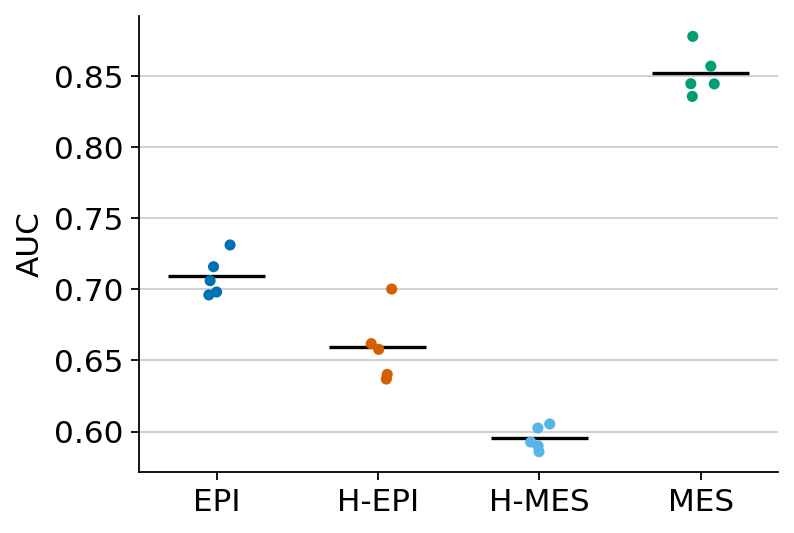

In [14]:
EMT_MAP = {0: "EPI", 1: "H-EPI", 2: "H-MES", 3: "MES"}
spice.pl.auc_per_class(adata, state_map=EMT_MAP, save=figures_dir + "breast_auc_per_class_hallmark_scanpy.pdf")

In [ ]:
spice.tl.explain_nodes(adata, n_explanations=300)  # increase to 300 for publication quality
spice.pl.node_importance(adata, state_map=EMT_MAP, save=figures_dir + "breast_node_importance_scanpy.pdf")

Computing node explanations for label 1...


Label 1: 100%|██████████| 300/300 [2:56:55<00:00, 35.39s/it]  


Computing node explanations for label 0...


Label 0:  98%|█████████▊| 295/300 [2:20:46<06:28, 77.78s/it]  

In [ ]:
adata.write_h5ad("processed_data/xenium_breast_hallmark_spice_results_scanpy.h5ad")

/home/cenk/miniconda3/envs/spice_env/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:982: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


/home/cenk/miniconda3/envs/spice_env/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:982: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/home/cenk/miniconda3/envs/spice_env/lib/python3.11/site-packages/squidpy/pl/_utils.py:95: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(path, **kwargs)
/home/cenk/miniconda3/envs/spice_env/lib/python3.11/site-packages/IPython/core/events.py:100: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)


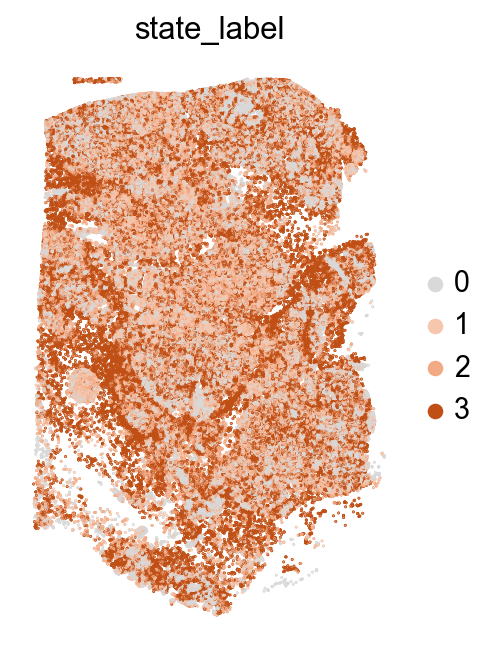

/home/cenk/miniconda3/envs/spice_env/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


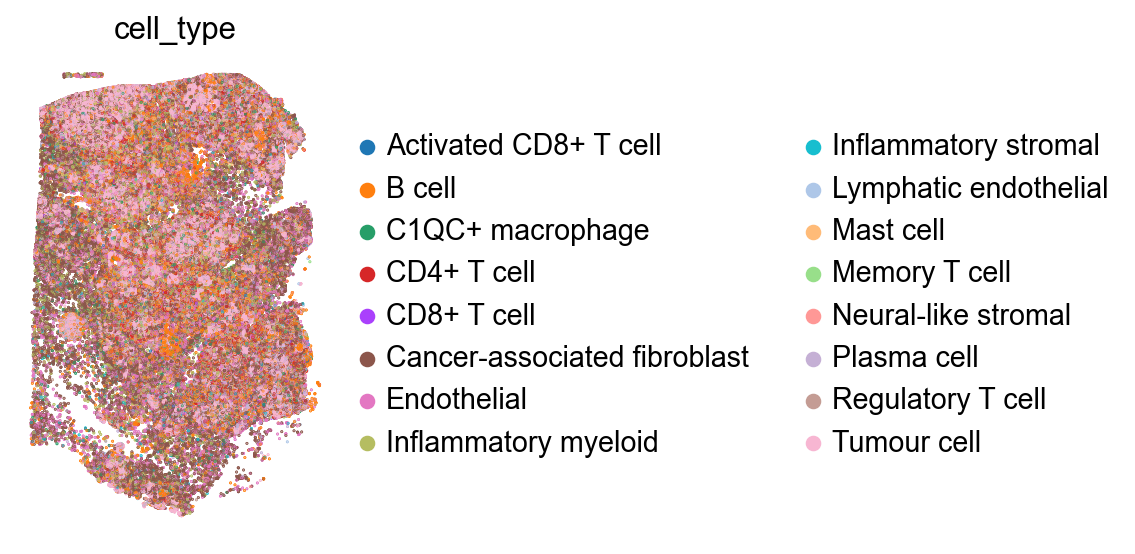

In [ ]:
import squidpy as sq
import scanpy as sc
sc.set_figure_params(frameon=False)

adata = sc.read_h5ad("processed_data/xenium_breast_hallmark_spice_results_scanpy.h5ad")
adata.obs["state_label"] = adata.obs["state_label"].astype("category")
adata.uns["state_label_colors"] = ["#D9D9D9", "#F6C6AD", "#F2AA84", "#C04F15"]

sq.pl.spatial_scatter(
    adata,
    shape=None,
    color=["state_label"],
    save="breast_spatial_scatter_state_label_scanpy.pdf",
)

sq.pl.spatial_scatter(
    adata,
    shape=None,
    color=["cell_type"],
    save="breast_spatial_scatter_cell_type_scanpy.pdf",
)